# EDA: CoMoFoD Small (imagem, copy-move)

Nicho: **imagem/multimídia**, detecção e localização de adulteração por copiar-e-colar (copy-move).

Fonte: CoMoFoD, Univ. de Zagreb (Tralić et al., ELMAR 2013). Termos do *release agreement*: uso acadêmico e não comercial, sem redistribuir nem modificar as imagens baixadas, citando o artigo. Por isso este notebook **só lê** as imagens e não as grava em lugar nenhum além do `data/interim/` (ignorado pelo git).

Perguntas: (1) a estrutura da base é íntegra? (2) quantas cenas independentes existem de fato? (3) o que as máscaras marcam? (4) uma característica global simples separa original de falsificada? (5) o que isso diz sobre a viabilidade de IA?

In [1]:
from pathlib import Path
import re
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd
from PIL import Image
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score, accuracy_score

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)
ROOT = Path.cwd().parent
D = ROOT / "data/interim/comofod/CoMoFoD_small_v2"
SEED = 42

## 1. Inventário e integridade

In [2]:
arq = sorted(p for p in D.iterdir() if p.suffix in (".png", ".jpg"))
pat = re.compile(r"^(\d{3})_(O|F|B|M)(?:_(BC|CA|CR|IB|JC|NA)(\d))?\.(png|jpg)$")
rows = []
for p in arq:
    m = pat.match(p.name)
    rows.append(dict(arquivo=p.name, cena=int(m[1]), tipo=m[2], pos=m[3] or "", nivel=int(m[4]) if m[4] else 0, ext=m[5], bytes=p.stat().st_size))
df = pd.DataFrame(rows)
print("arquivos de imagem:", len(df), "| cenas:", df.cena.nunique(), "| fora do padrão de nome:", len(arq) - len(df))
print("arquivos por cena (distintos):", df.groupby("cena").size().unique())
print(df.groupby(["tipo", "ext"]).size().unstack(fill_value=0))
print("tamanho total das imagens: %.2f GB" % (df.bytes.sum() / 1e9))

arquivos de imagem: 10400 | cenas: 200 | fora do padrão de nome: 0
arquivos por cena (distintos): [52]
ext    jpg   png
tipo            
B        0   200
F     1800  3200
M        0   200
O     1800  3200
tamanho total das imagens: 3.21 GB


Cada cena deveria ter: 4 imagens-base (`O` original, `F` falsificada, `B` e `M` máscaras) e, para `O` e para `F`, 3 níveis de cada um de 5 pós-processamentos (BC, CA, CR, IB, NA) e 9 níveis de compressão JPEG (JC).

In [3]:
esperado = {("O", p): n for p, n in [("", 1), ("BC", 3), ("CA", 3), ("CR", 3), ("IB", 3), ("NA", 3), ("JC", 9)]}
esperado.update({("F", p): n for p, n in [("", 1), ("BC", 3), ("CA", 3), ("CR", 3), ("IB", 3), ("NA", 3), ("JC", 9)]})
esperado.update({("B", ""): 1, ("M", ""): 1})
obs = df.groupby(["cena", "tipo", "pos"]).size()
ruim = [(c, k) for c in df.cena.unique() for k, n in esperado.items() if obs.get((c, *k), 0) != n]
print("combinações fora do esperado:", len(ruim), ruim[:5])
assert not ruim and (df.groupby("cena").size() == 52).all() and len(df) == 10400, "estrutura da base diferente da esperada"
print("total esperado por cena:", sum(esperado.values()), "| total:", 200 * sum(esperado.values()))

combinações fora do esperado: 0 []
total esperado por cena: 52 | total: 10400


### 1.1 Categoria de manipulação (do `readme.txt`)

In [4]:
cats = {}; cat = None
for linha in (D / "readme.txt").read_text().splitlines():
    t = linha.strip()
    if t in ("TRANSLATION", "ROTATION", "SCALING", "DISTORTION", "COMBINATION"): cat = t; continue
    m = re.match(r"^(\d{3})\s+(.*)$", t)
    if m and cat: cats[int(m[1])] = (cat, m[2])
cena = pd.DataFrame([dict(cena=c, categoria=v[0], detalhe=v[1]) for c, v in sorted(cats.items())])
# área da região copiada (px), antes da transformação = primeiro número da linha do readme
cena["area_px"] = cena.detalhe.str.extract(r"^(\d+)")[0].astype(float)
print("cenas no readme:", len(cena), "| cenas sem categoria:", sorted(set(range(1, 201)) - set(cena.cena)))
print(cena.categoria.value_counts().to_string())
print("\nárea da região copiada (px, de 262.144):")
print(cena.area_px.describe().round(0).to_string())

cenas no readme: 200 | cenas sem categoria: []
categoria
COMBINATION    41
TRANSLATION    40
ROTATION       40
SCALING        40
DISTORTION     39

área da região copiada (px, de 262.144):
count      200.0
mean      7169.0
std       9320.0
min        360.0
25%       1651.0
50%       3369.0
75%      10376.0
max      37542.0


## 2. Propriedades das imagens e das máscaras

In [5]:
base = df[df.tipo.isin(["O", "F", "B", "M"]) & (df.pos == "")]
def info(n):
    with Image.open(D / n) as im: return im.size, im.mode
meta = pd.DataFrame([(a, *info(a)) for a in base.arquivo], columns=["arquivo", "tam", "modo"]).merge(base[["arquivo", "tipo"]])
print(meta.groupby(["tipo", "tam", "modo"]).size().to_string())

tipo  tam         modo
B     (512, 512)  RGB     126
                  RGBA     74
F     (512, 512)  RGB     196
                  RGBA      4
M     (512, 512)  RGB     162
                  RGBA     38
O     (512, 512)  RGB     195
                  RGBA      5


As máscaras `B` marcam o quê? Conferência objetiva: o conjunto de pixels em que `F` difere de `O` coincide com a máscara?

In [6]:
def carrega(n, modo="RGB"):
    with Image.open(D / n) as im: return np.asarray(im.convert(modo))

def mascara(c):
    b = carrega(f"{c:03d}_B.png", "L") > 127
    return b

def linha(c):
    o, f = carrega(f"{c:03d}_O.png").astype(int), carrega(f"{c:03d}_F.png").astype(int)
    dif = (np.abs(o - f).sum(axis=2) > 0)
    b = mascara(c)
    inter = (dif & b).sum()
    return dict(cena=c, frac_mascara=b.mean(), frac_dif=dif.mean(), cobertura_dif_na_mascara=inter / max(dif.sum(), 1),
                iou=inter / max((dif | b).sum(), 1))

with ThreadPoolExecutor(8) as ex: viz = pd.DataFrame(list(ex.map(linha, range(1, 201)))).merge(cena[["cena", "categoria", "area_px"]])
print(viz[["frac_mascara", "frac_dif", "cobertura_dif_na_mascara", "iou"]].describe().round(4).to_string())
print("cenas sem nenhuma diferença O x F:", int((viz.frac_dif == 0).sum()))
print(f"cenas em que O e F diferem em mais de 50% dos pixels: {int((viz.frac_dif > .5).sum())} | em mais de 20%: {int((viz.frac_dif > .2).sum())}")
loc = viz[viz.frac_dif <= .2]
print(f"nas {len(loc)} cenas com diferença localizada (<= 20% dos pixels): cobertura mediana {loc.cobertura_dif_na_mascara.median():.3f}, IoU mediano {loc.iou.median():.3f}")
print("correlação entre log(área do readme) e log(área da máscara B):", round(np.corrcoef(np.log(viz.area_px), np.log(viz.frac_mascara * 512 * 512))[0, 1], 3))

       frac_mascara  frac_dif  cobertura_dif_na_mascara       iou
count      200.0000  200.0000                  200.0000  200.0000
mean         0.0551    0.1972                    0.8303    0.4293
std          0.0678    0.3631                    0.3696    0.2219
min          0.0027    0.0013                    0.0034    0.0034
25%          0.0168    0.0091                    1.0000    0.3357
50%          0.0258    0.0163                    1.0000    0.4990
75%          0.0792    0.0817                    1.0000    0.5183
max          0.2904    0.9997                    1.0000    0.9993
cenas sem nenhuma diferença O x F: 0
cenas em que O e F diferem em mais de 50% dos pixels: 35 | em mais de 20%: 37
nas 163 cenas com diferença localizada (<= 20% dos pixels): cobertura mediana 1.000, IoU mediano 0.500
correlação entre log(área do readme) e log(área da máscara B): 0.976


             frac_mascara     iou
categoria                        
COMBINATION        0.0234  0.5101
DISTORTION         0.0272  0.4985
ROTATION           0.0214  0.4865
SCALING            0.0278  0.2376
TRANSLATION        0.0243  0.5000

cenas com diferença global (O e F diferem em > 50% dos pixels), por categoria:
             com_dif_global  cenas
categoria                         
COMBINATION               0     41
DISTORTION                0     39
ROTATION                 18     40
SCALING                  17     40
TRANSLATION               0     40


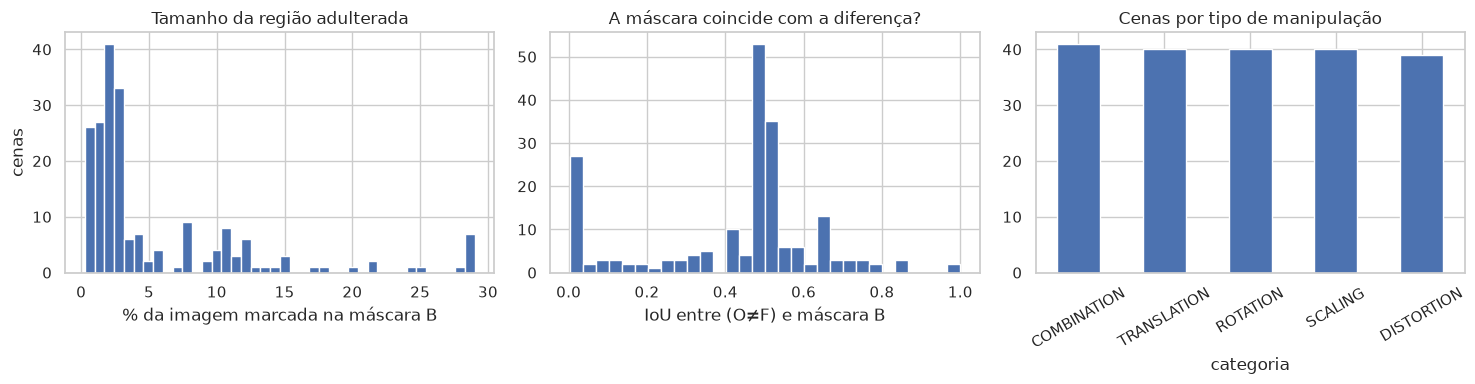

In [7]:
print(viz.groupby("categoria")[["frac_mascara", "iou"]].median().round(4).to_string())
print("\ncenas com diferença global (O e F diferem em > 50% dos pixels), por categoria:")
print(viz.assign(global_=viz.frac_dif > .5).groupby("categoria").global_.agg(["sum", "size"]).rename(columns={"sum": "com_dif_global", "size": "cenas"}).to_string())
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(viz.frac_mascara * 100, bins=40); ax[0].set(xlabel="% da imagem marcada na máscara B", ylabel="cenas", title="Tamanho da região adulterada")
ax[1].hist(viz.iou, bins=30); ax[1].set(xlabel="IoU entre (O≠F) e máscara B", title="A máscara coincide com a diferença?")
viz.categoria.value_counts().plot.bar(ax=ax[2], rot=30); ax[2].set(title="Cenas por tipo de manipulação")
plt.tight_layout(); plt.show()

In [8]:
# O release agreement proíbe redistribuir as imagens; embutir uma cena na saída do notebook (que vai para o repositório) seria publicá-la.
# Ative só localmente e não versione a saída.
EXIBIR_EXEMPLO = False
c = int(viz.sort_values("frac_mascara").iloc[len(viz) // 2].cena)
print(f"cena de exemplo (mediana da área marcada): {c}  ->  {c:03d}_O.png, {c:03d}_F.png, {c:03d}_B.png, {c:03d}_M.png")
if EXIBIR_EXEMPLO:
    fig, ax = plt.subplots(1, 4, figsize=(16, 4))
    for a, (t, n) in zip(ax, [("original", f"{c:03d}_O.png"), ("falsificada", f"{c:03d}_F.png"), ("máscara B", f"{c:03d}_B.png"), ("máscara M", f"{c:03d}_M.png")]):
        a.imshow(carrega(n, "RGB")); a.set_title(f"cena {c}: {t}"); a.axis("off")
    plt.tight_layout(); plt.show()

cena de exemplo (mediana da área marcada): 59  ->  059_O.png, 059_F.png, 059_B.png, 059_M.png


## 3. Pós-processamentos e PSNR

In [9]:
ps = pd.read_csv(D / "psnr.txt", sep=r"\s+", header=None, names=["arquivo", "psnr"])
ps = ps.merge(df[["arquivo", "tipo", "pos", "nivel"]], on="arquivo", how="left")
print("linhas no psnr.txt:", len(ps), "| sem correspondência no inventário:", int(ps.tipo.isna().sum()))
print(ps.groupby("tipo").size().to_dict())
print(ps.pivot_table(index="pos", columns="nivel", values="psnr", aggfunc="median").round(1).to_string())
pp = df[df.tipo.isin(["O", "F"]) & (df.pos != "")]
cob = pp.merge(ps[["arquivo", "psnr"]], on="arquivo", how="left")
print(f"\nvariantes pós-processadas de O e F: {len(pp):,} | com PSNR: {int(cob.psnr.notna().sum())} ({cob.psnr.notna().mean():.2%})")
print(cob.groupby(["tipo", "pos"]).psnr.apply(lambda x: f"{x.notna().sum()}/{len(x)}").unstack(0).to_string())

linhas no psnr.txt: 600 | sem correspondência no inventário: 0
{'O': 600}
nivel     1     2     3
pos                    
NA     20.7  23.1  33.0

variantes pós-processadas de O e F: 9,600 | com PSNR: 600 (6.25%)
tipo       F        O
pos                  
BC     0/600    0/600
CA     0/600    0/600
CR     0/600    0/600
IB     0/600    0/600
JC    0/1800   0/1800
NA     0/600  600/600


## 4. Quantas amostras independentes? Um baseline simples

In [10]:
# 10.000 imagens classificáveis (O e F, base + 24 variantes cada); as 400 máscaras não entram
cls = df[df.tipo.isin(["O", "F"])].reset_index(drop=True)
cls["y"] = (cls.tipo == "F").astype(int)
print("imagens classificáveis:", len(cls), "| originais:", int((cls.y == 0).sum()), "| falsificadas:", int(cls.y.sum()))
print("cenas:", cls.cena.nunique(), "-> cada cena gera", len(cls) // cls.cena.nunique(), "imagens (1 base + 24 variantes, de cada classe)")

imagens classificáveis: 10000 | originais: 5000 | falsificadas: 5000
cenas: 200 -> cada cena gera 50 imagens (1 base + 24 variantes, de cada classe)


### 4.1 As 200 cenas são fotografias distintas?

O `readme.txt` repete as mesmas áreas de região copiada em categorias diferentes, o que sugere que a mesma fotografia é reaproveitada. Teste objetivo: comparar as 200 imagens originais (`O`) por correlação de miniaturas 32x32 em tons de cinza e agrupar as que são a mesma foto.

In [11]:
from scipy.sparse.csgraph import connected_components
def miniatura(c):
    return np.asarray(Image.open(D / f"{c:03d}_O.png").convert("L").resize((32, 32), Image.BILINEAR), dtype=np.float32).ravel()
T = np.array([miniatura(c) for c in range(1, 201)])
T = (T - T.mean(1, keepdims=True)) / T.std(1, keepdims=True)
C = T @ T.T / T.shape[1]; np.fill_diagonal(C, 0)
print("correlação entre miniaturas de cenas diferentes (quantis 50/90/99/99,9%):", np.quantile(C[np.triu_indices(200, 1)], [.5, .9, .99, .999]).round(3))
for th in (.9, .95, .98):
    n, lab = connected_components(C > th, directed=False)
    print(f"limiar {th}: {n} fotografias distintas")
n_fotos, lab = connected_components(C > .95, directed=False)
foto = pd.DataFrame({"cena": range(1, 201), "foto": lab}).merge(cena[["cena", "categoria"]])
tam = foto.groupby("foto").size()
print(f"\ntamanho dos grupos (cenas por fotografia): mínimo {tam.min()}, mediana {int(tam.median())}, máximo {tam.max()}; fotografias usadas em mais de uma cena: {(tam > 1).sum()} de {n_fotos}")
print("fotografias que aparecem nas 5 categorias de manipulação:", int((foto.groupby("foto").categoria.nunique() == 5).sum()))
cls["foto"] = cls.cena.map(foto.set_index("cena").foto)

correlação entre miniaturas de cenas diferentes (quantis 50/90/99/99,9%): [-0.005  0.244  1.     1.   ]
limiar 0.9: 41 fotografias distintas
limiar 0.95: 41 fotografias distintas
limiar 0.98: 41 fotografias distintas

tamanho dos grupos (cenas por fotografia): mínimo 1, mediana 4, máximo 13; fotografias usadas em mais de uma cena: 37 de 41
fotografias que aparecem nas 5 categorias de manipulação: 8


### 4.2 Baseline

12 características globais (média e desvio por canal RGB, variância do laplaciano, energia de gradiente em x e y, razão de alta frequência, média e desvio em tons de cinza). Validação cruzada de 5 dobras, repetida com 5 sorteios de grupos, em três cenários: **por imagem** (variantes da mesma cena misturadas), **por cena** e **por fotografia** (nenhuma foto aparece em treino e teste ao mesmo tempo).

In [12]:
def feats(n):
    a = carrega(n).astype(np.float32)
    g = a.mean(axis=2)
    lap = g[1:-1, 1:-1] * 4 - g[:-2, 1:-1] - g[2:, 1:-1] - g[1:-1, :-2] - g[1:-1, 2:]
    gx, gy = np.diff(g, axis=1), np.diff(g, axis=0)
    F = np.abs(np.fft.fftshift(np.fft.fft2(g - g.mean())))
    yy, xx = np.indices(F.shape); r = np.hypot(yy - 256, xx - 256)
    return [*a.mean(axis=(0, 1)), *a.std(axis=(0, 1)), lap.var(), (gx ** 2).mean(), (gy ** 2).mean(), F[r > 64].sum() / F.sum(), g.mean(), g.std()]

with ThreadPoolExecutor(8) as ex: Xf = np.array(list(ex.map(feats, cls.arquivo)))
nomes = ["mR", "mG", "mB", "sR", "sG", "sB", "lap_var", "grad_x", "grad_y", "alta_freq", "m_gray", "s_gray"]
y = cls.y.to_numpy()
print(Xf.shape, "(imagens, características)")
print("AUC de cada característica sozinha (0,5 = não separa):")
print(pd.Series({n: roc_auc_score(y, Xf[:, i]) for i, n in enumerate(nomes)}).round(3).to_string())

(10000, 12) (imagens, características)
AUC de cada característica sozinha (0,5 = não separa):
mR           0.493
mG           0.500
mB           0.506
sR           0.504
sG           0.506
sB           0.503
lap_var      0.499
grad_x       0.501
grad_y       0.498
alta_freq    0.496
m_gray       0.501
s_gray       0.504


In [13]:
def cv(modelo, X, y, grupos, sementes=range(5), k=5):
    ug = np.unique(grupos); aucs, accs = [], []
    for sd in sementes:
        dobra = dict(zip(ug, np.random.default_rng(sd).permutation(len(ug)) % k))
        f = np.array([dobra[g] for g in grupos]); s = np.zeros(len(y))
        for i in range(k):
            tr, te = f != i, f == i
            assert not set(grupos[tr]) & set(grupos[te]), "grupo em treino e teste"
            modelo.fit(X[tr], y[tr]); s[te] = modelo.predict_proba(X[te])[:, 1]
        aucs.append(roc_auc_score(y, s)); accs.append(accuracy_score(y, s >= .5))
    return dict(AUC=np.mean(aucs), AUC_dp=np.std(aucs), acuracia=np.mean(accs))

rf = RandomForestClassifier(n_estimators=100, n_jobs=4, random_state=SEED)
lr = LogisticRegression(max_iter=2000)
Z = (Xf - Xf.mean(0)) / (Xf.std(0) + 1e-9)
grupos = {"por imagem (vaza variantes)": np.arange(len(y)), "por cena": cls.cena.to_numpy(), "por fotografia": cls.foto.to_numpy()}
rows = {}
for gn, g in grupos.items():
    rows[(gn, "RandomForest")] = cv(rf, Xf, y, g)
    rows[(gn, "LogReg")] = cv(lr, Z, y, g)
print(pd.DataFrame(rows).T.round(3).to_string())

                                            AUC  AUC_dp  acuracia
por imagem (vaza variantes) RandomForest  0.984   0.001     0.936
                            LogReg        0.502   0.004     0.499
por cena                    RandomForest  0.967   0.002     0.902
                            LogReg        0.521   0.001     0.504
por fotografia              RandomForest  0.495   0.007     0.499
                            LogReg        0.510   0.000     0.504


In [14]:
# controle: só as 400 imagens-base (sem variantes), por fotografia
b = np.flatnonzero((cls.pos == "").to_numpy())
print("só imagens-base, RandomForest, por fotografia:", {k: round(v, 3) for k, v in cv(rf, Xf[b], y[b], cls.foto.to_numpy()[b]).items()})

só imagens-base, RandomForest, por fotografia: {'AUC': np.float64(0.5), 'AUC_dp': np.float64(0.007), 'acuracia': np.float64(0.498)}


---
## 5. Veredito de viabilidade para IA

Números abaixo vêm das saídas deste notebook (uma execução; baseline com 12 características globais e sem ajuste de hiperparâmetros; média de 5 sorteios de grupos).

### Escala real: 41 fotografias, não 200 cenas
- 10.400 arquivos, 200 cenas, 10.000 imagens classificáveis (5.000 originais e 5.000 falsificadas). Estrutura íntegra: todas as cenas têm exatamente os 52 arquivos esperados.
- **As 200 cenas vêm de apenas 41 fotografias distintas** (resultado igual nos limiares 0,90, 0,95 e 0,98 de correlação de miniaturas). Uma fotografia aparece em até 13 cenas (mediana 4), 37 das 41 são usadas em mais de uma cena e 8 aparecem nas 5 categorias de manipulação. O método é simples (miniaturas 32x32 em tons de cinza), mas o resultado é estável.
- Consequência: qualquer divisão treino/teste precisa **agrupar por fotografia**. Agrupar por cena, como o `readme.txt` sugere, ainda vaza.

### Baseline: o sinal desaparece quando o vazamento é removido
| Divisão | RandomForest (AUC) | Regressão logística (AUC) |
|---|---|---|
| por imagem (variantes misturadas) | 0,984 | 0,502 |
| por cena | 0,967 | 0,521 |
| **por fotografia** | **0,495** | 0,510 |

Nenhuma característica sozinha separa as classes (AUC de 0,49 a 0,51). O random forest só "funciona" quando a mesma fotografia aparece em treino e teste: ele memoriza as estatísticas de cada foto e a pequena diferença entre `O` e `F` dentro dela. Esse mecanismo é a explicação compatível com o colapso para o acaso, mas não foi testado de forma direta. Com as 400 imagens-base, por fotografia, o AUC também é 0,50.

### Máscaras
- `B` marca regiões pequenas: mediana de 2,6% da imagem (de 0,3% a 29%). A correlação (em log) com a área do `readme.txt` é 0,976.
- Nas 163 cenas com diferença localizada, a máscara cobre 100% dos pixels em que `O` e `F` diferem (mediana) e o IoU mediano é 0,50. É compatível com `B` marcando **região de origem e região colada**, enquanto `O≠F` só vê a colada; é uma leitura dos números, não está documentada. Em escala o IoU mediano cai para 0,24.

### Artefato global em rotação e escala
Em **35 cenas (17,5%) `O` e `F` diferem em mais de 50% dos pixels**, não só na região copiada: 18 das 40 cenas de rotação e 17 das 40 de escala, e nenhuma das outras três categorias. A causa não está documentada. Para um detector, isso é um possível atalho (aprender o processamento global em vez da adulteração); não foi investigado.

### Pós-processamentos e PSNR
O `psnr.txt` tem 600 linhas e cobre só **ruído (NA) sobre originais** (`O`), 6,25% das 9.600 variantes pós-processadas. Brilho, contraste, redução de cor, desfoque e JPEG, e todas as variantes de `F`, ficam sem PSNR. A mediana é 20,7 / 23,1 / 33,0 dB nos níveis 1, 2 e 3.

### Conclusão
- **Para classificar "original ou falsificada":** características globais simples **não são viáveis** nesta base; o resultado é acaso com validação correta.
- **Para treinar um modelo:** 41 fotografias é pequeno demais para treino profundo. O valor realista é **benchmark de robustez** (as variantes pós-processadas) e **teste de transferência** de um detector treinado em outra base. Isso é uma hipótese de uso, não medida aqui.
- **Não avaliado:** localização em nível de pixel, detectores copy-move clássicos e redes convolucionais.
- **Condições de uso (release agreement):** uso acadêmico e não comercial, sem redistribuir nem modificar as imagens, citando Tralić, Zupancic, Grgić e Grgić, ELMAR 2013. Este notebook só lê as imagens.